In [ ]:
!pip install koreanize-matplotlib
import koreanize_matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 27.7 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
import statsmodels.formula.api as smf
import statsmodels.api as sm


In [ ]:
df = pd.read_csv('week12_data.csv', encoding='cp949')
df

,환자ID,나이,성별,흡연,BMI,혈압,혈당,콜레스테롤,운동시간,진단,약물복용,체중_전,체중_후
0,P001,53,남,N,20.3,117,92,146,0.1,건강,N,60.8,58.7
1,P002,37,남,N,23.1,122,129,139,5.9,건강,N,69.1,68.9
2,P003,59,남,Y,20.6,147,116,144,1.0,건강,N,61.7,61.2
3,P004,61,여,N,26.3,143,90,216,8.1,주의,Y,71.6,68.5
4,P005,30,남,Y,30.4,131,110,171,4.6,위험,Y,91.0,90.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,P196,39,남,N,20.5,114,70,151,2.2,건강,N,61.4,61.0
196,P197,57,남,N,25.3,110,96,152,9.2,건강,N,75.7,75.1
197,P198,45,여,N,24.2,114,121,169,1.1,건강,N,65.9,66.4
198,P199,49,여,N,19.8,123,76,170,5.0,건강,N,53.9,52.1


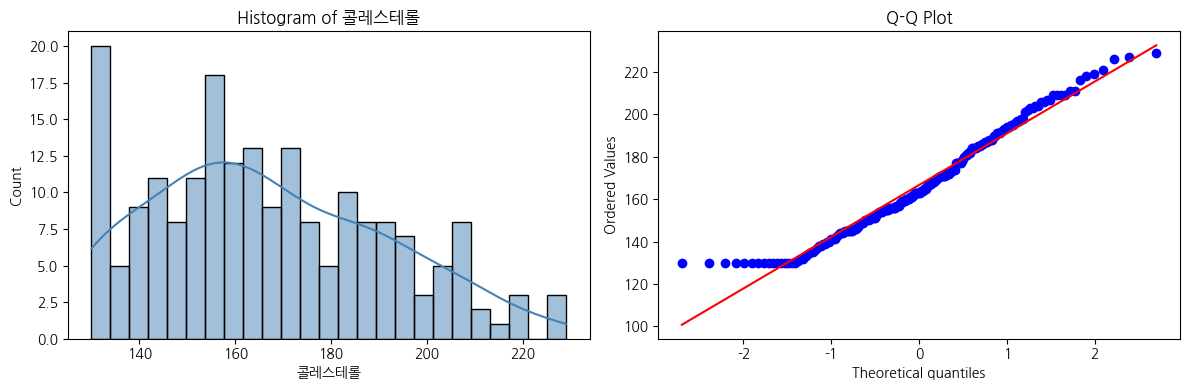

In [ ]:
#예제1
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 좌측: 히스토그램 + KDE
sns.histplot(df['콜레스테롤'], kde=True, bins=25, ax=axes[0], color='steelblue')
axes[0].set_title('Histogram of 콜레스테롤')

# 우측: QQ-plot
stats.probplot(df['콜레스테롤'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

In [ ]:
#예제2
cols = ['콜레스테롤', '혈당', 'BMI', '운동시간']
results = []
for col in cols:
    data = df[col].dropna()
    stat, p = stats.shapiro(data)
    verdict = '정규성 만족' if p > 0.05 else '정규성 위배'
    results.append({'변수': col, '통계량': round(stat, 4),
                    'p-value': round(p, 4), '판정': verdict})

print(pd.DataFrame(results))


      변수     통계량  p-value      판정
0  콜레스테롤  0.9656   0.0001  정규성 위배
1     혈당  0.9580   0.0000  정규성 위배
2    BMI  0.9906   0.2184  정규성 만족
3   운동시간  0.8478   0.0000  정규성 위배


In [ ]:
#예제3
x = df['운동시간'].dropna()

# 변환 전
print(f'[변환 전]  왜도 = {x.skew():.3f}, '
      f'Shapiro p = {stats.shapiro(x)[1]:.4f}')

# log1p = log(1 + x) — 0 입력에 안전
x_log = np.log1p(x)

print(f'[로그 변환] 왜도 = {x_log.skew():.3f}, '
      f'Shapiro p = {stats.shapiro(x_log)[1]:.4f}')


[변환 전]  왜도 = 1.401, Shapiro p = 0.0000
[로그 변환] 왜도 = 0.252, Shapiro p = 0.0004


In [ ]:
#예제4
x = df['혈당'].dropna()

# Box-Cox 변환 + 최적 λ 산출
transformed, lam = stats.boxcox(x)

print(f'최적 λ = {lam:.3f}')
print(f'변환 전 왜도 = {x.skew():.3f}')
print(f'변환 후 왜도 = {pd.Series(transformed).skew():.3f}')

# 해석
if abs(lam) < 0.2:
    print('→ 로그 변환에 가까움')
elif abs(lam - 0.5) < 0.15:
    print('→ 제곱근 변환에 가까움')
else:
    print(f'→ λ={lam:.2f} 의 거듭제곱 변환')


최적 λ = -0.440
변환 전 왜도 = 0.611
변환 후 왜도 = 0.022
→ λ=-0.44 의 거듭제곱 변환


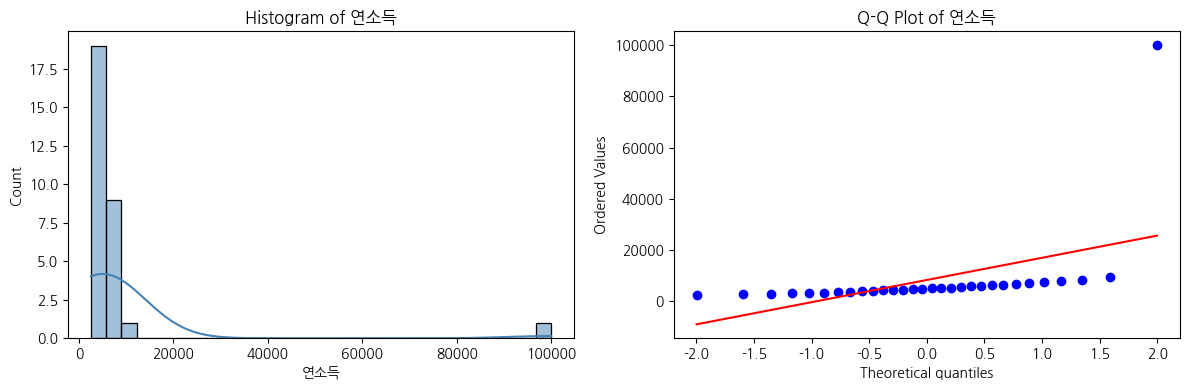

왜도 = 5.391


In [ ]:
#슬라이드 17 정규화 예제
#Q1
df = pd.read_csv('week11_shop.csv', encoding='cp949')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 좌: 히스토그램 + KDE
sns.histplot(df['연소득'], kde=True, bins=30, ax=axes[0], color='steelblue')
axes[0].set_title('Histogram of 연소득')

# 우: QQ-plot
stats.probplot(df['연소득'], dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot of 연소득')

plt.tight_layout()
plt.show()

print(f"왜도 = {df['연소득'].skew():.3f}")

In [ ]:
#슬라이드 17 정규화 예제
#Q2
x = df['연소득']
stat, p = stats.shapiro(x)

print(f"통계량 = {stat:.4f}")
print(f"p-value = {p:.4e}")

if p > 0.05:
    print("→ 정규성 만족 (H₀ 채택)")
else:
    print("→ 정규성 위배 (H₀ 기각)")

통계량 = 0.2587
p-value = 3.2154e-11
→ 정규성 위배 (H₀ 기각)


In [ ]:
#슬라이드 17 정규화 예제
#Q3
x_log = np.log1p(df['연소득'])   # log(1+x) — 0 입력 안전

print(f"변환 전 왜도 = {df['연소득'].skew():.3f}")
print(f"변환 후 왜도 = {x_log.skew():.3f}")
print(f"왜도 감소량 = {df['연소득'].skew() - x_log.skew():.3f}")

변환 전 왜도 = 5.391
변환 후 왜도 = 3.244
왜도 감소량 = 2.147


In [ ]:
#슬라이드 17 정규화 예제
#Q4

x_bc, lam = stats.boxcox(df['연소득'])

print(f"최적 λ = {lam:.3f}")
print(f"변환 후 왜도 = {pd.Series(x_bc).skew():.3f}")

# λ 해석
if abs(lam) < 0.15:
    print("→ λ ≈ 0 : 로그 변환과 거의 동일")
elif abs(lam - 0.5) < 0.15:
    print("→ λ ≈ 0.5 : 제곱근 변환에 가까움")
elif abs(lam - 1) < 0.15:
    print("→ λ ≈ 1 : 변환 거의 없음")
else:
    print(f"→ λ = {lam:.2f} 의 거듭제곱 변환")

최적 λ = -0.935
변환 후 왜도 = 0.034
→ λ = -0.94 의 거듭제곱 변환


In [ ]:
#슬라이드 17 정규화 예제
#Q5
results = []
for name, data in [('원본', df['연소득']),
                   ('로그 변환', x_log),
                   (f'Box-Cox (λ={lam:.2f})', x_bc)]:
    stat, p = stats.shapiro(data)
    results.append({
        '변환': name,
        '왜도': round(pd.Series(data).skew(), 3),
        'Shapiro 통계량': round(stat, 4),
        'p-value': f'{p:.4e}'
    })

print(pd.DataFrame(results).to_string(index=False))
#print(pd.DataFrame(results).to_string(index=False, col_space=15)) #테이블이 너무 가까우면, 열 크기를 15로 고정.

               변환    왜도  Shapiro 통계량    p-value
               원본 5.391       0.2587 3.2154e-11
            로그 변환 3.244       0.6924 1.2135e-06
Box-Cox (λ=-0.94) 0.034       0.9842 9.2260e-01


In [ ]:
#예제5
df = pd.read_csv('week12_data.csv', encoding='cp949')

bp = df['혈압']
t_stat, p = stats.ttest_1samp(bp, popmean=120)

print(f'표본 평균 = {bp.mean():.2f} mmHg')
print(f't 통계량 = {t_stat:.3f}')
print(f'p-value  = {p:.4f}')

if p < 0.05:
    print('→ 정상 기준 120과 통계적으로 유의한 차이가 있다.')
else:
    print('→ 정상 기준 120과 유의한 차이가 없다.')


표본 평균 = 121.73 mmHg
t 통계량 = 2.105
p-value  = 0.0366
→ 정상 기준 120과 통계적으로 유의한 차이가 있다.


In [ ]:
#예제6
yes = df[df['흡연']=='Y']['혈압']
no  = df[df['흡연']=='N']['혈압']

# 1단계: 등분산 검정
_, lev_p = stats.levene(yes, no)
print(f'Levene p = {lev_p:.4f}')

# 2단계: 등분산 결과에 따라 t-test
equal_var = lev_p > 0.05
t, p = stats.ttest_ind(yes, no, equal_var=equal_var)

print(f'흡연자 평균   = {yes.mean():.2f}')
print(f'비흡연자 평균 = {no.mean():.2f}')
print(f't = {t:.3f}, p = {p:.4f}')


Levene p = 0.4811
흡연자 평균   = 130.92
비흡연자 평균 = 118.67
t = 7.210, p = 0.0000


In [ ]:
#예제7
before = df['체중_전']
after  = df['체중_후']

t, p = stats.ttest_rel(before, after)

print(f'평균 차이 (전-후) = {(before - after).mean():.2f} kg')
print(f't = {t:.3f}, p = {p:.4f}')

if p < 0.05:
    print('→ 체중 변화가 통계적으로 유의하다.')
else:
    print('→ 체중 변화가 유의하지 않다.')


평균 차이 (전-후) = 0.65 kg
t = 6.606, p = 0.0000
→ 체중 변화가 통계적으로 유의하다.


In [ ]:
#예제8
# 1단계: ANOVA
groups = [df[df['진단']==g]['BMI'] for g in ['건강', '주의', '위험']]
f_stat, p = stats.f_oneway(*groups)
print(f'F = {f_stat:.3f}, p = {p:.4f}')

# 2단계: Tukey HSD 사후검정
result = pairwise_tukeyhsd(endog=df['BMI'],
                           groups=df['진단'], alpha=0.05)
print(result)


F = 80.011, p = 0.0000
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
    건강     위험    6.272   0.0  4.7224  7.8215   True
    건강     주의   3.8749   0.0  2.9575  4.7922   True
    위험     주의  -2.3971 0.002 -4.0384 -0.7558   True
---------------------------------------------------


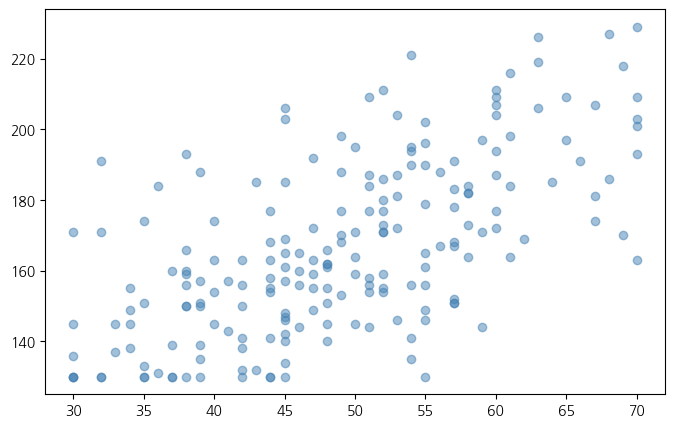

In [ ]:
plt.figure(figsize=(8, 5))
plt.scatter(df['나이'], df['콜레스테롤'], alpha=0.5, color='steelblue')

In [ ]:
#예제9
# 회귀 적합
model = smf.ols('콜레스테롤 ~ 나이', data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                  콜레스테롤   R-squared:                       0.398
Model:                            OLS   Adj. R-squared:                  0.395
Method:                 Least Squares   F-statistic:                     130.7
Date:                Tue, 26 May 2026   Prob (F-statistic):           1.42e-23
Time:                        03:46:58   Log-Likelihood:                -872.78
No. Observations:                 200   AIC:                             1750.
Df Residuals:                     198   BIC:                             1756.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     91.3015      6.730     13.566      0.0

In [ ]:

# 시각화
plt.figure(figsize=(8, 5))
plt.scatter(df['나이'], df['콜레스테롤'], alpha=0.5, color='steelblue')
plt.plot(df['나이'], model.fittedvalues, color='red', lw=2)
plt.xlabel('나이'); plt.ylabel('콜레스테롤')
plt.title(f'R² = {model.rsquared:.3f}')
plt.show()

In [ ]:
#예제10

# 다중회귀 적합
model = smf.ols(
    '콜레스테롤 ~ 나이 + BMI + 혈압', data=df).fit()

# 회귀 요약 (계수·p-value·R²)
print(model.summary())

# ANOVA 테이블 (각 변수의 SS, F, p)
print(sm.stats.anova_lm(model, typ=2))


                            OLS Regression Results                            
Dep. Variable:                  콜레스테롤   R-squared:                       0.631
Model:                            OLS   Adj. R-squared:                  0.625
Method:                 Least Squares   F-statistic:                     111.5
Date:                Wed, 13 May 2026   Prob (F-statistic):           3.65e-42
Time:                        06:54:01   Log-Likelihood:                -823.88
No. Observations:                 200   AIC:                             1656.
Df Residuals:                     196   BIC:                             1669.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.8741     13.622     -0.211      0.8